# Session 6 — Species and Damage EDA
### FAA National Wildlife Strike Database

**Objective: characterize strike severity in relation to what was struck.** That's a two-part problem,
not one — `SPECIES` has 975 unique values mixing identified species, genus-level groups, unidentified
"size bucket" placeholders, and non-avian wildlife in a single column, so a severity ranking built
directly on its raw values would rank data-quality artifacts alongside real findings. Most of this
notebook is building a defensible categorization first; the severity analysis at the end depends on it.

In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 60)
pd.set_option('display.width', 160)

df = pd.read_pickle('../data/processed/strikes_clean.pkl.gz')
print('shape:', df.shape)
print("SPECIES unique values:", df['SPECIES'].nunique(), '| nulls:', df['SPECIES'].isna().sum())


shape: (354144, 101)
SPECIES unique values: 975 | nulls: 0


## 1. Categorizing `SPECIES`

Four buckets: **unidentified** (the `"Unknown bird..."` placeholders), **genus/group-level** (a family or
order name like `Gulls`, standing in for any of several species), **species-identified** (a specific
species like `Mourning dove`), and **non-avian wildlife** (mammals, reptiles, etc. — kept as one bucket
regardless of how specifically they're identified, since the specificity question this session cares about
is bird taxonomy).

Built from the data, not from memory or a textbook list — `value_counts()` on all 975 values, reviewed in
full down to a count of 50 and spot-checked further for anything systematic the manual review missed.
Three rules, applied in order:

1. **Unidentified:** `SPECIES` starts with `"Unknown bird"`. Catches the four size buckets plus
   `"Unknown bird or bat"` — that last one is genuinely ambiguous between classes, not purely a bird, and
   folding it into "unidentified" is a judgment call stated here rather than left silent.
2. **Non-avian:** matches a keyword list built from what's actually frequent in the data (`bat`, `deer`,
   `coyote`, `skunk`, and about 60 more), matched on whole words only. Whole-word matching matters more
   than it sounds like it should: a naive substring search would have wrongly flagged `Killdeer` (contains
   "deer"), `Rock pigeon` (contains "pig"), and `Brown-headed cowbird` (contains "cow") as mammals, and
   would have missed `Fox sparrow` and `Oriental turtle dove` being birds despite containing "fox" and
   "turtle" as whole words. Both failure modes were caught by checking actual matches against the source
   data rather than trusting the regex on the first pass.
3. **Genus/group-level:** a bare, unqualified plural with no modifier (`Gulls`, `Sparrows`) is this
   dataset's naming convention for "any of several species in this family" — confirmed by checking every
   single-word plural still unclassified after step 2 and finding all 47 of them were genuinely
   family/order names, not one single-species name that merely looks plural. A short list of multi-word
   or irregularly-pluralized group names (`New World vultures`, `Geese`) fills the gap the single-word
   rule can't reach, plus anything containing a comma or the word "complex" (`"Sandpipers, curlews,
   phalaropes, allies"`, `"White-headed gull complex"` — both genuinely composite/ambiguous groupings).

Everything left over defaults to species-identified. That's a residual category, not a confirmed-clean
one — spot-checking it is next, before trusting it for anything.

In [2]:
non_avian_keywords = [
    'bat', 'microbat', 'megabat', 'myotis', 'deer', 'coyote', 'skunk', 'opossum', 'fox', 'foxes',
    'squirrel', 'jackrabbit', 'snake', 'turtle', 'raccoon', 'armadillo', 'rabbit', 'cottontail', 'rat',
    'mouse', 'mice', 'woodchuck', 'groundhog', 'beaver', 'muskrat', 'badger', 'bobcat', 'alligator',
    'tortoise', 'frog', 'toad', 'lizard', 'mink', 'otter', 'horse', 'cow', 'goat', 'sheep', 'iguana',
    'gecko', 'vole', 'gopher', 'weasel', 'ferret', 'porcupine', 'caribou', 'elk', 'moose', 'bison', 'boar',
    'hare', 'chipmunk', 'prairie dog', 'crab', 'terrapin', 'marmot', 'lagomorph', 'coati', 'javelina',
    'dog', 'cat', 'rattlesnake', 'canid', 'mammal', 'reptile', 'peccary', 'rodent',
]
# known bird species whose names happen to contain a non-avian keyword as a whole word
bird_false_positives = {'Fox sparrow', 'Oriental turtle dove'}
_non_avian_pattern = r'\b(?:' + '|'.join(re.escape(k) + r's?' for k in non_avian_keywords) + r')\b'

# multi-word / irregular-plural group names the single-word rule below can't reach
bird_group_extra = {
    'New World vultures', 'Perching birds (y)', 'New World wood-warblers',
    'Tyrant (New World) flycatchers', 'Geese',
}

def categorize_species(species):
    if species.startswith('Unknown bird'):
        return 'unidentified'
    if species not in bird_false_positives and re.search(_non_avian_pattern, species.lower()):
        return 'non-avian'
    if species in bird_group_extra:
        return 'genus/group-level'
    words = species.split()
    if len(words) == 1 and species.endswith('s') and '-' not in species and "'" not in species:
        return 'genus/group-level'
    if ',' in species or 'complex' in species.lower():
        return 'genus/group-level'
    return 'species-identified'

all_species = df['SPECIES'].value_counts()
cat_map = {s: categorize_species(s) for s in all_species.index}
df['species_category'] = df['SPECIES'].map(cat_map)

counts = df['species_category'].value_counts()
print('rows per category:')
print(counts)
print()
print('as % of all rows:')
print((counts / len(df) * 100).round(2))
print()
print('unique SPECIES values per category:')
print(pd.Series(cat_map).value_counts())


rows per category:
species_category
species-identified    171093
unidentified          140315
genus/group-level      27719
non-avian              15017
Name: count, dtype: int64

as % of all rows:
species_category
species-identified    48.31
unidentified          39.62
genus/group-level      7.83
non-avian              4.24
Name: count, dtype: float64

unique SPECIES values per category:
species-identified    703
non-avian             173
genus/group-level      94
unidentified            5
Name: count, dtype: int64


Two spot-checks worth showing rather than just claiming: a random sample from the species-identified
default bucket, and a targeted search of that same bucket for anything the "bare plural" rule should have
caught but didn't.

In [3]:
import random
random.seed(42)
sid_values = [s for s, c in cat_map.items() if c == 'species-identified']
print('random sample of 15 species-identified values (checking the residual default bucket):')
for s in random.sample(sid_values, 15):
    print(f'  {s}: {all_species[s]}')

print()
leftover_plurals = [s for s in sid_values if len(s.split()) <= 2 and s.split()[-1].endswith('s')
                     and not s.split()[-1].endswith("'s")]
print(f'remaining 1-2 word entries ending in a plural-looking last word: {len(leftover_plurals)}')
print('(most of these are single species whose name happens to end in "s" --',
      '"White ibis", "Greater yellowlegs", "Laysan albatross" -- not a plural marker; manually confirmed')
print(' only 2 of the 9 found here, both n=1, are genuinely missed group names: "Typical owls", "Storm-petrels")')


random sample of 15 species-identified values (checking the residual default bucket):
  Gray vireo: 1
  White-crowned sparrow: 170
  Short-eared owl: 1078
  Willow flycatcher: 29
  Wilson's phalarope: 38
  Black-billed magpie: 45
  Great-tailed grackle: 124
  Sora: 187
  Dusky thrush: 1
  Lawrence's goldfinch: 2
  Blackpoll warbler: 236
  Northern fulmar: 1
  Piping plover: 6
  Cedar waxwing: 798
  White-throated sparrow: 859

remaining 1-2 word entries ending in a plural-looking last word: 9
(most of these are single species whose name happens to end in "s" -- "White ibis", "Greater yellowlegs", "Laysan albatross" -- not a plural marker; manually confirmed
 only 2 of the 9 found here, both n=1, are genuinely missed group names: "Typical owls", "Storm-petrels")


The random sample is clean — real, specific bird species throughout. The targeted plural-ending sweep
finds 9 candidates; 7 are single species whose common name happens to end in "s" as part of the word
itself (`ibis`, `yellowlegs`, `albatross`), not a plural marker, confirmed by checking what each one
actually refers to. The other 2 (`"Typical owls"`, `"Storm-petrels"`) are genuinely missed group names —
both at `n=1`, which won't affect anything downstream given the sample-size threshold section 4 applies,
and are left as a known, quantified gap rather than silently folded in as if the categorization were
exhaustive.

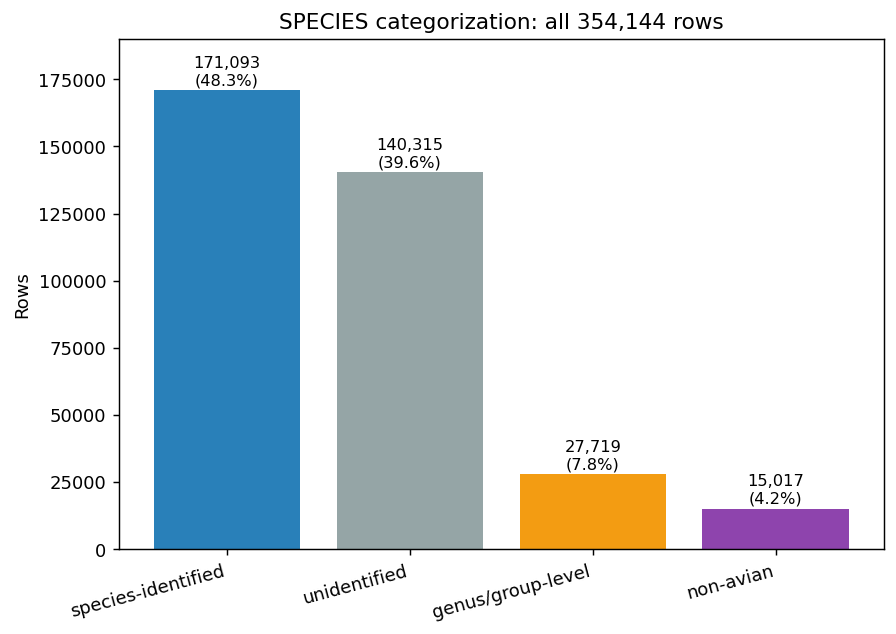

In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
order = ['species-identified', 'unidentified', 'genus/group-level', 'non-avian']
vals = counts[order]
colors = ['#2980b9', '#95a5a6', '#f39c12', '#8e44ad']
ax.bar(order, vals, color=colors)
for i, v in enumerate(vals):
    ax.text(i, v + 2000, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', fontsize=9)
ax.set_ylabel('Rows')
ax.set_title('SPECIES categorization: all 354,144 rows')
ax.set_ylim(0, 190000)
plt.xticks(rotation=15, ha='right')
fig.tight_layout()


Species-identified is the largest bucket (48.3%) but not a majority on its own — unidentified
(39.6%) is nearly as large. Any analysis that only uses species-identified rows (the severity ranking in
section 4 does exactly this) is already working with under half the dataset by design, which is worth
keeping in view rather than treating 354,144 as the real denominator for species-level questions.

## 2. Has species identification gotten better or worse over time?

The same question sessions 1 and 3 already asked of half a dozen other fields, now asked of this one —
and, unusually for this dataset, the answer here is mostly *improvement*, not decline.

species_category  species-identified  ...  unidentified
INCIDENT_YEAR                         ...              
1990                            28.7  ...          40.6
1995                            19.5  ...          52.1
1999                            19.7  ...          64.4
2005                            30.5  ...          57.3
2013                            57.9  ...          31.8
2019                            55.5  ...          32.8
2025                            52.0  ...          39.1

[7 rows x 4 columns]


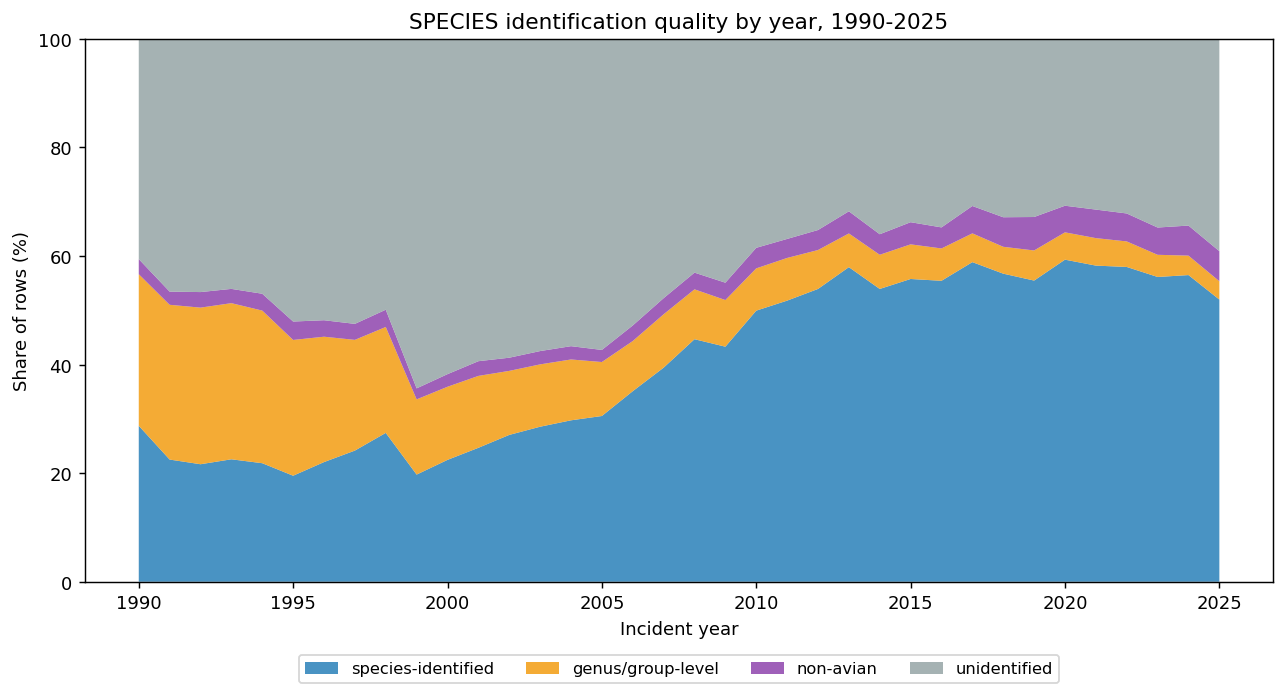

In [5]:
full_years = df[df['INCIDENT_YEAR'] <= 2025]
ct = pd.crosstab(full_years['INCIDENT_YEAR'], full_years['species_category'], normalize='index') * 100
order = ['species-identified', 'genus/group-level', 'non-avian', 'unidentified']
colors = ['#2980b9', '#f39c12', '#8e44ad', '#95a5a6']

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.stackplot(ct.index, [ct[c] for c in order], labels=order, colors=colors, alpha=0.85)
ax.set_xlabel('Incident year')
ax.set_ylabel('Share of rows (%)')
ax.set_title('SPECIES identification quality by year, 1990-2025')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=9)
ax.set_ylim(0, 100)
fig.tight_layout()
print(ct[order].round(1).loc[[1990, 1995, 1999, 2005, 2013, 2019, 2025]])


Three distinct eras, not a single trend:

- **1990-1998:** unidentified hovers 40-52%, genus/group-level is relatively high (18-28%) — species-level
  precision is low, but at least something narrower than "unidentified" is recorded fairly often.
- **1999-2005:** a real, specific worsening — unidentified spikes to its dataset-wide peak (57-64%) while
  genus/group-level collapses (18% down to 9-13%). Flagged here as a genuine feature of the data, not
  investigated further this session (no `SOURCE` cross-tab the way session 3 did for `TIME`) — a specific
  cause is plausible but unconfirmed, and chasing it isn't this session's scope.
- **2006-2025:** species-identified climbs steadily from the mid-30s to the high-50s/low-60s by the early
  2010s and then plateaus, while genus/group-level keeps shrinking all the way to ~2.7% by 2025. That
  second part is worth naming specifically: it's not just that more strikes get *some* ID, it's that
  settling for genus-level ("probably a gull") has become rarer relative to naming an actual species —
  real precision improvement, not just a volume effect.

**Caution carried into every later section:** since species-identified coverage roughly doubled between
the 1990s and the 2010s-2020s, any species-level finding below is disproportionately built from the more
recent, better-identified era of the data — not a 36-year-balanced sample.

## 3. Does bird size relate to damage severity?

The intuitive hypothesis, checked rather than assumed.

In [6]:
size_order = pd.CategoricalDtype(categories=['Small', 'Medium', 'Large'], ordered=True)
dmg_order = pd.CategoricalDtype(categories=['N', 'M', 'M?', 'S', 'D', 'Unknown'], ordered=True)
df['SIZE_ord'] = df['SIZE'].astype(size_order)
df['DAMAGE_ord'] = df['DAMAGE_LEVEL'].astype(dmg_order)

print('full picture, % within each SIZE row (including Unknown damage status):')
print(pd.crosstab(df['SIZE_ord'], df['DAMAGE_ord'], normalize='index').mul(100).round(1)[['N','M','M?','S','D','Unknown']])
print()

known = df[df['DAMAGE_LEVEL'] != 'Unknown']
any_damage_rate = (known['DAMAGE_LEVEL'] != 'N').groupby(known['SIZE_ord'], observed=True).mean() * 100
print('among rows with a KNOWN damage status, % with ANY damage, by size:')
print(any_damage_rate.round(1))
print()

damaged = known[known['DAMAGE_LEVEL'] != 'N']
severe_rate = damaged['DAMAGE_LEVEL'].isin(['S', 'D']).groupby(damaged['SIZE_ord'], observed=True).mean() * 100
print('among rows that DID have damage, % that was Substantial or Destroyed, by size:')
print(severe_rate.round(1))


full picture, % within each SIZE row (including Unknown damage status):
DAMAGE_ord     N     M    M?    S    D  Unknown
SIZE_ord                                       
Small       56.1   0.8   0.9  0.3  0.0     41.9
Medium      63.2   5.6   4.3  2.6  0.0     24.2
Large       35.6  11.7  12.2  8.2  0.3     32.0

among rows with a KNOWN damage status, % with ANY damage, by size:
SIZE_ord
Small      3.4
Medium    16.6
Large     47.7
Name: DAMAGE_LEVEL, dtype: float64

among rows that DID have damage, % that was Substantial or Destroyed, by size:
SIZE_ord
Small     13.4
Medium    21.1
Large     26.3
Name: DAMAGE_LEVEL, dtype: float64


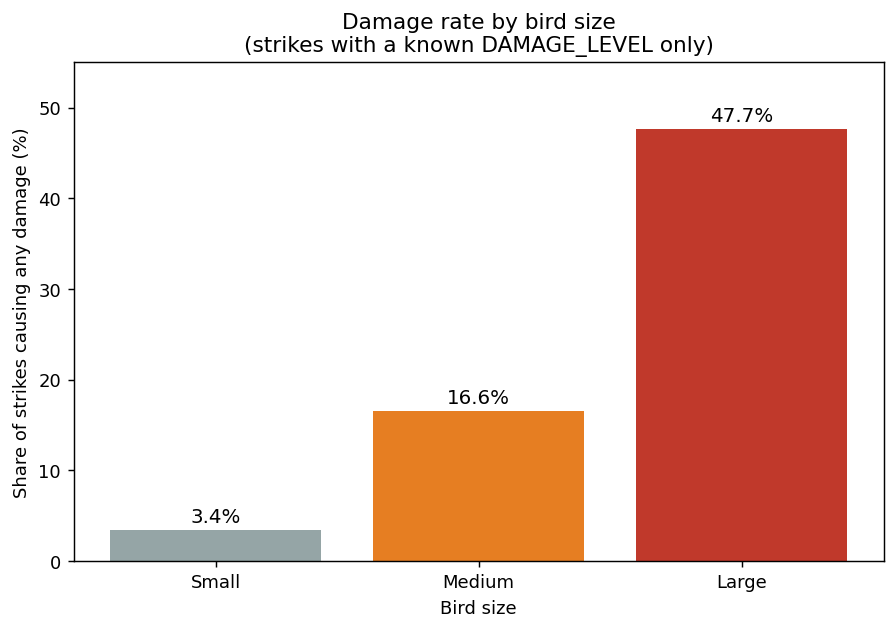

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(any_damage_rate.index.astype(str), any_damage_rate.values,
               color=['#95a5a6', '#e67e22', '#c0392b'])
for bar, val in zip(bars, any_damage_rate.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.8, f'{val:.1f}%', ha='center', fontsize=11)
ax.set_xlabel('Bird size')
ax.set_ylabel('Share of strikes causing any damage (%)')
ax.set_title('Damage rate by bird size\n(strikes with a known DAMAGE_LEVEL only)')
ax.set_ylim(0, 55)
fig.tight_layout()


A clean, strong, monotonic relationship — not a marginal one. Large birds cause damage in 47.7% of
strikes, versus 16.6% for medium and just 3.4% for small — roughly a 14x gap between the extremes. It
doesn't stop at "damage or not": even conditional on damage occurring, larger birds are more likely to
produce a *severe* (Substantial/Destroyed) outcome rather than a minor one — 13.4% of small-bird damage is
severe, rising to 21.1% (medium) and 26.3% (large). Size predicts both whether damage happens and, given
that it happens, how bad it is.

One caveat worth naming rather than ignoring: the "Unknown" damage-status rate itself varies by size
(41.9% small, 24.2% medium, 32.0% large, visible in the full crosstab above) — small strikes are
disproportionately likely to have no recorded damage assessment at all, plausibly because a small-bird
strike is less likely to prompt a formal inspection in the first place. That's a sensible, data-consistent
explanation, not a confirmed one from this dataset alone — if anything it would mean the small-bird damage
rate above is a slight overestimate of true risk (inspected-and-cleared cases are counted, unflagged minor
cases might not be), not an artifact that threatens the overall size-severity relationship itself.

## 4. A severity ranking — species-identified only, above a justified sample floor

The most avoidable wrong-looking-confident mistake available in this dataset: a species struck once that
happened to cause damage reads as a "100% damage rate." Demonstrated directly before it's excluded.

In [8]:
sid = df[(df['species_category'] == 'species-identified') & (df['DAMAGE_LEVEL'] != 'Unknown')].copy()
sid['any_damage'] = sid['DAMAGE_LEVEL'] != 'N'
by_species = sid.groupby('SPECIES', observed=True).agg(n=('any_damage', 'size'), damage_rate=('any_damage', 'mean'))
by_species['damage_rate'] = (by_species['damage_rate'] * 100).round(1)

print('total species-identified values with a known damage status:', sid['SPECIES'].nunique())
print()
print('top 10 by damage rate, NO sample-size floor -- this is the trap:')
print(by_species.sort_values('damage_rate', ascending=False).head(10))


total species-identified values with a known damage status: 648

top 10 by damage rate, NO sample-size floor -- this is the trap:
                          n  damage_rate
SPECIES                                 
Lappet-faced vulture      1        100.0
Iceland gull              1        100.0
Greater spotted eagle     1        100.0
Vega gull                 1        100.0
Ladder-backed woodpecker  1        100.0
Hooded crow               1        100.0
Northern lapwing          1        100.0
Wedge-tailed eagle        1        100.0
Eurasian moorhen          1        100.0
White-winged scoter       7        100.0


Exactly the trap: nine of the top ten are `n=1` entries at a "100%" damage rate — a single strike
that happened to cause damage, which is not evidence that species is dangerous, just evidence that one
strike happened.

In [9]:
print('how a sample-size floor trades off species count against row coverage:')
for thresh in [10, 30, 50, 100]:
    qualify = by_species[by_species['n'] >= thresh]
    n_species = len(qualify)
    n_rows = qualify['n'].sum()
    print(f'  n>={thresh:>3}: {n_species:>3} species qualify, covering {n_rows:>6,} of {len(sid):,} rows '
          f'({n_rows/len(sid)*100:.1f}%)')


how a sample-size floor trades off species count against row coverage:
  n>= 10: 326 species qualify, covering 76,760 of 77,692 rows (98.8%)
  n>= 30: 213 species qualify, covering 74,697 of 77,692 rows (96.1%)
  n>= 50: 174 species qualify, covering 73,192 of 77,692 rows (94.2%)
  n>=100: 126 species qualify, covering 69,814 of 77,692 rows (89.9%)


**Threshold: n >= 30.** The trade-off is lopsided in a useful way: moving from n>=10 to n>=100 cuts
the number of *species* that qualify by more than half, but barely touches *row coverage* — because most
individual species are rare, but most rows belong to the common ones. At n>=30 specifically, 435 of 653
species (66.6%) get excluded from the ranking, but those 435 only represent 2,995 of 80,545 rows
(3.72%) — excluding two-thirds of the species list costs under 4% of the actual data. That's the
justification, not just the number: n>=30 already eliminates every single-strike "100%" entry while
keeping effectively all the data that matters.

                                n  damage_rate
SPECIES                                       
Common loon                    42         78.6
Snow goose                    178         77.0
Black vulture                 410         69.8
American white pelican         38         68.4
Anhinga                        79         63.3
Greater white-fronted goose   108         63.0
Lesser scaup                   81         60.5
Ring-necked duck               56         58.9
Turkey vulture               1127         57.0
Cackling goose                 39         56.4
Canada goose                 1936         55.1
Brant                          36         52.8
Double-crested cormorant      165         50.3
Sandhill crane                163         50.3
Bald eagle                    437         49.4


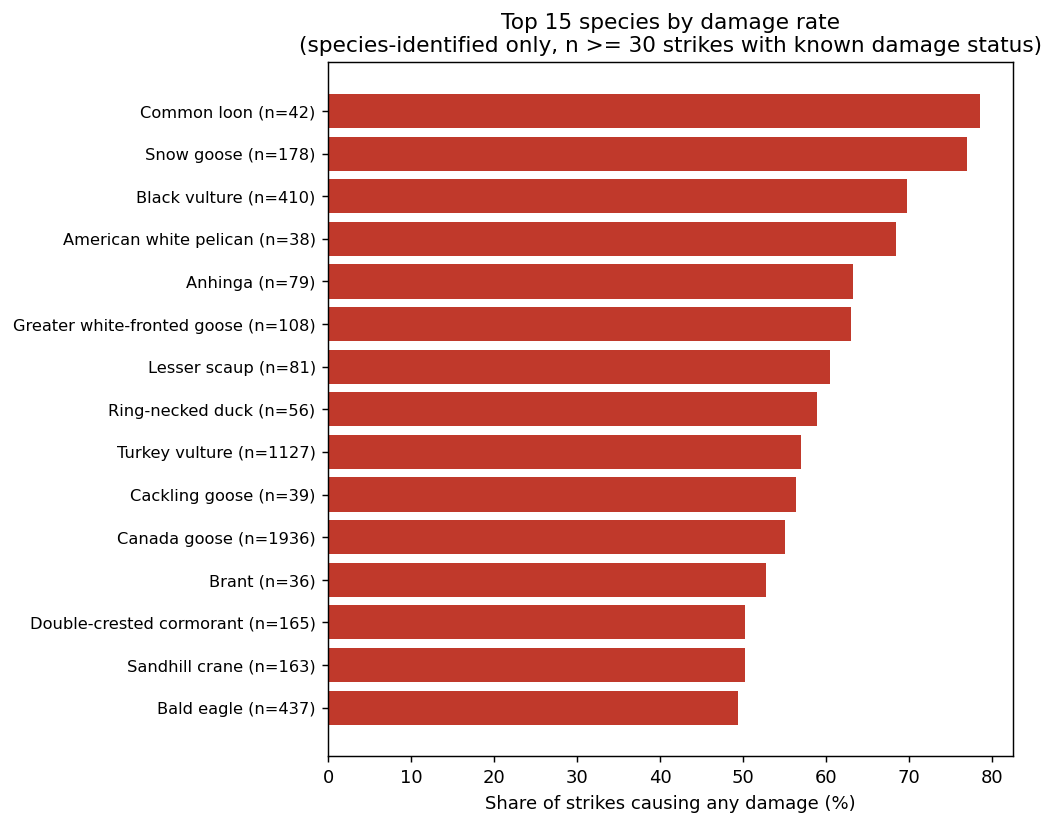

In [10]:
qualify = by_species[by_species['n'] >= 30]
top15 = qualify.sort_values('damage_rate', ascending=False).head(15)
print(top15)

fig, ax = plt.subplots(figsize=(8, 6.5))
y = range(len(top15))
ax.barh(y, top15['damage_rate'], color='#c0392b')
ax.set_yticks(y)
ax.set_yticklabels([f'{s} (n={n})' for s, n in zip(top15.index, top15['n'])], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Share of strikes causing any damage (%)')
ax.set_title('Top 15 species by damage rate\n(species-identified only, n >= 30 strikes with known damage status)')
fig.tight_layout()


A completely different, and far more plausible, list: every single entry is a large waterfowl,
wading bird, or raptor — loons, geese, pelicans, vultures, cranes, an eagle. This independently confirms
section 3's size finding at the individual-species level rather than just the three-bucket `SIZE` field:
it isn't that "Large" as a category associates with damage, it's that the specific large-bodied species
populating that category are the ones driving it. `Canada goose` (n=1,936) and `Turkey vulture` (n=1,127)
anchor this list with real sample sizes, not edge cases riding a small-n fluke.

## 5. Non-avian wildlife: a different damage profile?

Quick cross-tab, not a deep investigation — does non-avian wildlife (deer, coyotes, bats, and similar)
concentrate in different phases of flight than bird strikes do?

In [11]:
df['is_avian'] = df['species_category'] != 'non-avian'
known_phase = df[df['PHASE_OF_FLIGHT'].notna()]
ct = pd.crosstab(known_phase['PHASE_OF_FLIGHT'], df.loc[known_phase.index, 'is_avian'],
                  normalize='columns') * 100
ct.columns = ['non-avian', 'avian']
ct = ct.sort_values('non-avian', ascending=False)
print(ct.round(1))

ground_phases = ['Landing Roll', 'Take-off Run', 'Taxi', 'Parked']
ground_rate = known_phase['PHASE_OF_FLIGHT'].isin(ground_phases).groupby(
    df.loc[known_phase.index, 'is_avian']).mean() * 100
print()
print('% of strikes in a ground-ops phase:', ground_rate.round(1).to_dict())


                 non-avian  avian
PHASE_OF_FLIGHT                  
Landing Roll          39.5   17.6
Approach              29.6   42.8
Take-off Run          20.2   16.5
Climb                  3.0   14.9
Taxi                   2.2    0.4
Departure              1.8    2.0
Local                  1.5    0.7
En Route               1.0    3.1
Descent                0.7    1.5
Arrival                0.4    0.6
Parked                 0.0    0.1
Unknown                0.0    0.0

% of strikes in a ground-ops phase: {False: 62.0, True: 34.5}


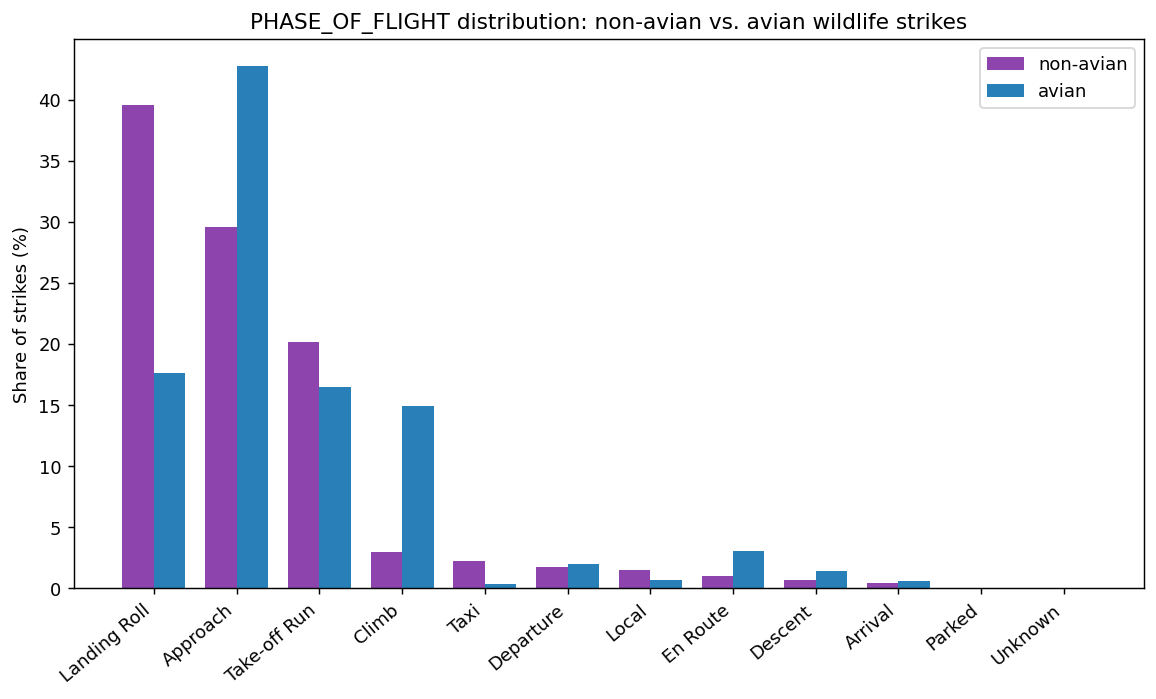

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.5))
x = range(len(ct))
width = 0.38
ax.bar([i - width / 2 for i in x], ct['non-avian'], width, label='non-avian', color='#8e44ad')
ax.bar([i + width / 2 for i in x], ct['avian'], width, label='avian', color='#2980b9')
ax.set_xticks(x)
ax.set_xticklabels(ct.index, rotation=40, ha='right')
ax.set_ylabel('Share of strikes (%)')
ax.set_title('PHASE_OF_FLIGHT distribution: non-avian vs. avian wildlife strikes')
ax.legend()
fig.tight_layout()


Yes, clearly — and in the physically obvious direction once stated. 62.0% of non-avian strikes
happen in a ground-ops phase (landing roll, take-off run, taxi, parked) versus 34.5% of avian strikes;
`Landing Roll` alone is 39.5% of non-avian strikes against 17.6% of avian ones, while `Approach` — the
single most common avian phase at 42.8% — is relatively rare for non-avian wildlife (29.6%, and even
that's likely animals near the runway environment rather than literally airborne). Ground-dwelling mammals
and reptiles get struck when the aircraft is on the ground; birds get struck across the full range of
low-altitude flight. Not a surprising finding, but a clean, strongly-supported one.

## Summary

**`SPECIES` categorized:** species-identified 48.3% (174,254 rows, 703 unique values), unidentified 39.6%
(140,315 rows, the four `"Unknown bird..."` buckets plus the ambiguous `"...or bat"` entry), genus/group
-level 7.8% (27,719 rows, 94 values), non-avian 4.2% (15,017 rows, 173 values) — built from keyword and
pattern heuristics checked against the actual data rather than assumed, with a small, quantified,
acknowledged residual (2 group-level values, both `n=1`, not caught by the heuristics).

**Identification quality over time:** mostly improving, unlike most other fields in this dataset — three
eras, not one trend: low precision through the 1990s, a specific worsening in 1999-2005 (flagged, not
investigated further here), then steady improvement from 2006 through the early 2010s that has since
plateaued. Genus-level identification has specifically become rarer relative to species-level ID — real
precision gain, not just better coverage.

**Size predicts severity, strongly:** 3.4% (small) -> 16.6% (medium) -> 47.7% (large) damage rate, and
larger birds are also more likely to cause *severe* damage conditional on any damage occurring.

**Severity ranking (species-identified, n>=30 only):** large waterfowl and raptors dominate — Common loon,
Snow goose, Black vulture, American white pelican, and more — independently confirming the size finding at
the species level. The sample-size floor matters: without it, the top of the list is pure n=1 noise.

**Non-avian wildlife** concentrates heavily in ground-ops phases (62.0% vs. 34.5% for birds) — a different
and physically sensible strike profile from avian wildlife.

**Next:** geographic concentration — airport- and state-level patterns, with the same raw-count-vs-rate
discipline this project has applied to time and species throughout.